# 08 - Naive Baselines (BijliCast)

**CT-378 lifecycle, step 4 - part 1: a simple baseline**

Before fitting any learner we establish the reference every model must beat:

| Baseline | Prediction | Uses fitting? |
|---|---|---|
| `persistence_lag_1h` | usage in the last known hour (`lag_1h`) | no |
| `seasonal_naive_lag_24h` | usage at the same hour yesterday (`lag_24h`) | no |
| `train_mean` | the training-split mean | one statistic from train |

All three use only columns that already exist in the feature frame, so there is
no leakage from validation or test. Metrics: **MAE** (primary, kWh), **RMSE**,
**R2**.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd()
while not (ROOT / "datasets").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("Repo root:", ROOT)

from src.models.baseline import PERSISTENCE_BASELINES, evaluate_baselines, load_splits
from src.models.metrics import metrics_table, pretty_metrics
from src.utils.config import FIGURES_DIR, HOUSE_COL, TABLES_DIR, TARGET, TIME_COL, ensure_dirs

ensure_dirs()
np.random.seed(42)


Repo root: D:\BijliCast


## 1. Load the chronological splits

Test is loaded only to report its size - it is **not** scored in this notebook.

In [2]:
train, val, test = load_splits()
for name, df in (("train", train), ("val", val), ("test", test)):
    print(f"{name:5s} rows {len(df):>7,} | {df[TIME_COL].min()} -> {df[TIME_COL].max()} | houses {df[HOUSE_COL].nunique()}")
print("\nTarget mean (kWh):", {n: round(float(d[TARGET].mean()), 4) for n, d in (("train", train), ("val", val), ("test", test))})
print("Test is NOT evaluated here - it stays untouched until notebook 11.")

train rows 336,053 | 2023-07-22 23:00:00 -> 2024-06-29 23:00:00 | houses 59
val   rows  71,995 | 2024-06-30 01:00:00 -> 2024-08-28 09:00:00 | houses 57
test  rows  72,059 | 2024-08-28 11:00:00 -> 2024-11-27 22:00:00 | houses 48

Target mean (kWh): {'train': 0.6255, 'val': 1.1206, 'test': 0.8363}
Test is NOT evaluated here - it stays untouched until notebook 11.


## 2. Persistence baselines on train and validation

No estimator is fitted; predictions are read directly from the lag columns.

In [3]:
train_mean = float(train[TARGET].mean())
rows = evaluate_baselines(train, "train", train_mean) + evaluate_baselines(val, "val", train_mean)
baseline_table = metrics_table(rows)
pretty_metrics(baseline_table)

,model,split,n,mae,rmse,r2,median_ae
0,persistence_lag_1h,train,336053,0.2235,0.4702,0.6814,0.0665
1,persistence_lag_1h,val,71995,0.3448,0.6263,0.6451,0.1359
2,seasonal_naive_lag_24h,train,336053,0.3072,0.6246,0.4379,0.0984
3,seasonal_naive_lag_24h,val,71995,0.4806,0.8114,0.4043,0.2208
4,train_mean,train,336053,0.5493,0.8331,0.0000,0.4252
5,train_mean,val,71995,0.7576,1.1621,-0.2218,0.4617


### Reading the table

- `persistence_lag_1h` is a very strong floor: the next hour is close to the
  current hour, so most of the signal is autocorrelation.
- The validation period is **summer** (mean target 1.12 kWh vs 0.63 in train),
  so its MAE is higher than train - a distribution shift, not over-fitting.
- `train_mean` has a negative R2 on validation: the level shifted.


### Plot 26 - validation MAE of each baseline

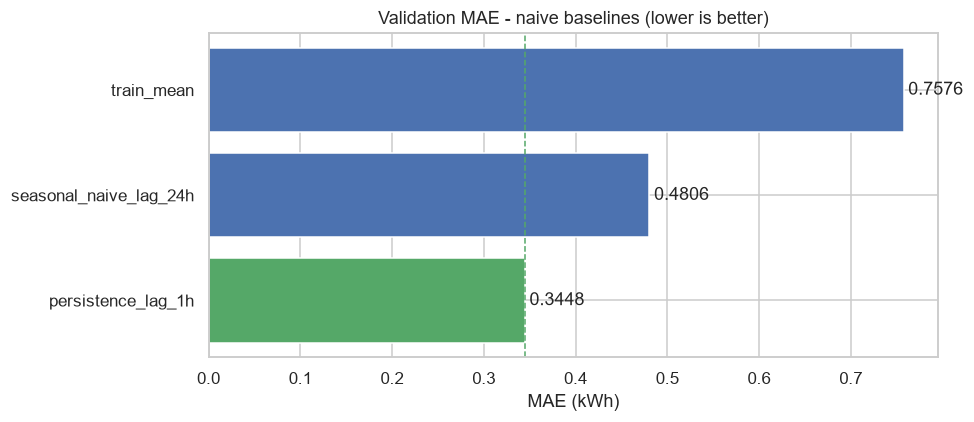

In [4]:
plot_df = baseline_table[baseline_table["split"] == "val"].sort_values("mae")
colors = ["#55A868" if m.startswith("persistence") else "#4C72B0" for m in plot_df["model"]]
plt.figure(figsize=(9, 4))
bars = plt.barh(plot_df["model"], plot_df["mae"], color=colors)
plt.bar_label(bars, fmt="%.4f", padding=3)
plt.axvline(plot_df.loc[plot_df["model"] == "persistence_lag_1h", "mae"].iloc[0],
            color="#55A868", ls="--", lw=1)
plt.title("Validation MAE - naive baselines (lower is better)")
plt.xlabel("MAE (kWh)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_baseline_val_mae.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 27 - persistence vs actual for the busiest validation household

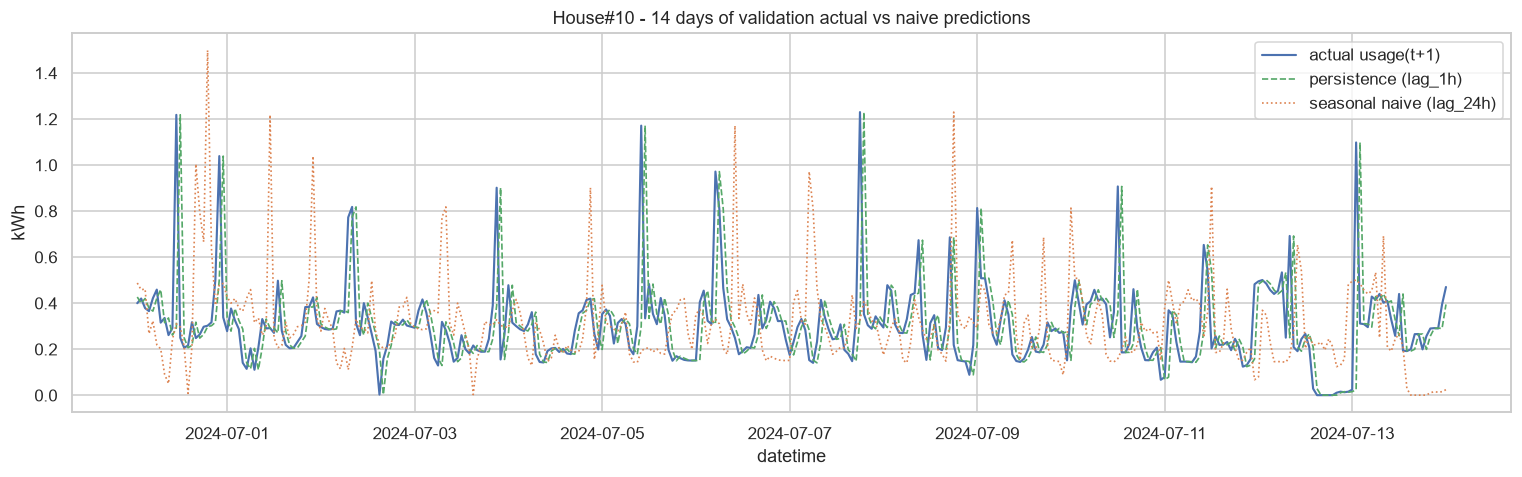

In [5]:
house = val.groupby(HOUSE_COL).size().idxmax()
g = (val[val[HOUSE_COL] == house]
     .sort_values(TIME_COL).set_index(TIME_COL).head(24 * 14))
plt.figure(figsize=(14, 4.5))
plt.plot(g.index, g[TARGET], label="actual usage(t+1)", color="#4C72B0", lw=1.4)
plt.plot(g.index, g["lag_1h"], label="persistence (lag_1h)", color="#55A868", ls="--", lw=1.1)
plt.plot(g.index, g["lag_24h"], label="seasonal naive (lag_24h)", color="#DD8452", ls=":", lw=1.1)
plt.title(f"{house} - 14 days of validation actual vs naive predictions")
plt.xlabel("datetime")
plt.ylabel("kWh")
plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_baseline_timeseries.png", dpi=220, bbox_inches="tight")
plt.show()

### Plot 28 - distribution of persistence errors on validation

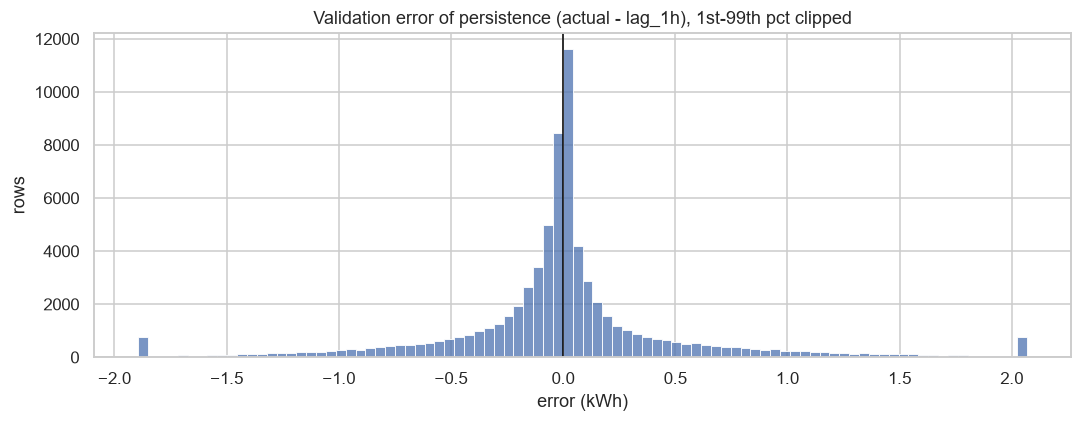

median error: -0.0014 | 95th pct |error|: 1.3642


In [6]:
err = val[TARGET] - val["lag_1h"]
lo, hi = err.quantile([0.01, 0.99])
plt.figure(figsize=(10, 4))
sns.histplot(err.clip(lo, hi), bins=90, color="#4C72B0")
plt.axvline(0, color="black", lw=1)
plt.title(f"Validation error of persistence (actual - lag_1h), 1st-99th pct clipped")
plt.xlabel("error (kWh)")
plt.ylabel("rows")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_baseline_error_distribution.png", dpi=220, bbox_inches="tight")
plt.show()
print("median error:", round(float(err.median()), 4), "| 95th pct |error|:", round(float(err.abs().quantile(0.95)), 4))

## 3. Save the baseline table

In [7]:
out = TABLES_DIR / "baseline_metrics.csv"
baseline_table.to_csv(out, index=False)
print("saved ->", out)

saved -> D:\BijliCast\reports\tables\baseline_metrics.csv


## Findings - Notebook 08

- The persistence baseline (`lag_1h`) is the bar to beat: its validation MAE is
  **0.3448 kWh** (R2 0.645). Seasonal naive (`lag_24h`) is clearly worse
  (0.4806 kWh), and the training mean is useless under the summer shift.
- Validation MAE > train MAE for every baseline because the target level rises
  from 0.63 to 1.12 kWh between the two periods. This is a **seasonal
  distribution shift**, not model over-fitting.
- Any learned model in notebook 09 must beat **0.3448 kWh validation MAE** to
  be useful; otherwise persistence would be the honest choice.
- The error distribution is right-skewed: most hours are predicted almost
  exactly, while a few high-usage spikes are badly under-predicted.
